<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS15/datasetPBL/Praktikum1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

In [2]:
# Load dan gabungkan kedua dataset milikmu
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))
df = df.dropna(subset=['text', 'rating_review']).reset_index(drop=True)

print(f"Jumlah total data ulasan & kafe: {len(df)}")
df[['cafe_id', 'name', 'rating_review', 'rating_cafe', 'text']].head()

Jumlah total data ulasan & kafe: 2230


,cafe_id,name,rating_review,rating_cafe,text
0,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,5.0,4.7,Hore!
1,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,5.0,4.7,Pelayanan bagus dan ramah apalagi barista yg p...
2,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,5.0,4.7,"comfort places for everything i did, mulai dar..."
3,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,5.0,4.7,"minumannya enak"", tempatnya comfy. worth to try"
4,ba4b512c-fa2d-4959-8384-8570c81121ec,ARTE COFFEE & EATERY,5.0,4.7,"kopian 24jam enak banget kalau dibuat wfc, tem..."


In [3]:
# Label encoding biner: 1 untuk Positif (rating_review >= 4), 0 untuk Negatif (rating_review < 4)
def label_encoder(rating):
    return 1 if rating >= 4 else 0

df['label'] = df['rating_review'].apply(label_encoder)
df['panjang_teks'] = df['text'].astype(str).apply(len)
df['teks_gabungan'] = df['name'].fillna('') + " " + df['text'].astype(str)

# Split data awal menjadi 80% training dan 20% testing (sebelum ekstraksi fitur agar bebas data leakage)
df_train, df_test = train_test_split(
    df, test_size=0.2, random_state=42, stratify=df['label']
)

y_train_all = df_train['label'].values
y_test      = df_test['label'].values

print(f"Jumlah data training: {len(df_train)}")
print(f"Jumlah data testing : {len(df_test)}")

Jumlah data training: 1784
Jumlah data testing : 446


In [4]:
fitur_num = ['rating_cafe', 'review_count', 'latitude', 'longitude', 'panjang_teks']

# Ekstraksi fitur teks TF-IDF (maksimal 500 fitur kata/frasa)
tfidf = TfidfVectorizer(max_features=500, ngram_range=(1, 2))
X_train_txt = tfidf.fit_transform(df_train['teks_gabungan']).toarray()
X_test_txt  = tfidf.transform(df_test['teks_gabungan']).toarray()

# Gabungkan fitur numerik dan fitur teks
X_train_feat = np.hstack([df_train[fitur_num].fillna(0).values, X_train_txt])
X_test_feat  = np.hstack([df_test[fitur_num].fillna(0).values, X_test_txt])

print("Shape fitur training:", X_train_feat.shape)
print("Shape fitur testing :", X_test_feat.shape)

Shape fitur training: (1784, 505)
Shape fitur testing : (446, 505)


In [5]:
# Menstandarisasi fitur menggunakan StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled  = scaler.transform(X_test_feat)

In [6]:
# Memisahkan data training menjadi 80% train dan 20% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train_all,
    test_size=0.2,
    random_state=42,
    stratify=y_train_all
)

In [7]:
# Pastikan seluruh label bertipe numpy array int/float32 untuk Keras
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

In [8]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        64,768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 73,089 (285.50 KB)

 Trainable params: 73,089 (285.50 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - accuracy: 0.8514 - loss: 0.3691 - val_accuracy: 0.8852 - val_loss: 0.2843
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9446 - loss: 0.1571 - val_accuracy: 0.9048 - val_loss: 0.2638
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9671 - loss: 0.0912 - val_accuracy: 0.9188 - val_loss: 0.2594
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9790 - loss: 0.0589 - val_accuracy: 0.9076 - val_loss: 0.2564
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9860 - loss: 0.0426 - val_accuracy: 0.9132 - val_loss: 0.2768
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9867 - loss: 0.0342 - val_accuracy: 0.9020 - val_loss: 0.2975
Epoch 7/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9895 - loss: 0.0299 - val_accuracy: 0.9020 - val_loss: 0.3172
Epoch 8/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9874 - loss: 0.0284 - val_accuracy: 0.8964 - val_los

In [10]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print(f"Loss Test    : {test_loss:.4f}")
print(f"Akurasi Test : {test_acc:.4f}")

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9215 - loss: 0.3062 
Loss Test    : 0.3062
Akurasi Test : 0.9215


14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
Classification Report:
               precision    recall  f1-score   support

 Negatif (0)       0.65      0.61      0.63        49
 Positif (1)       0.95      0.96      0.96       397

    accuracy                           0.92       446
   macro avg       0.80      0.79      0.79       446
weighted avg       0.92      0.92      0.92       446

Confusion Matrix:
 [[ 30  19]
 [ 16 381]]


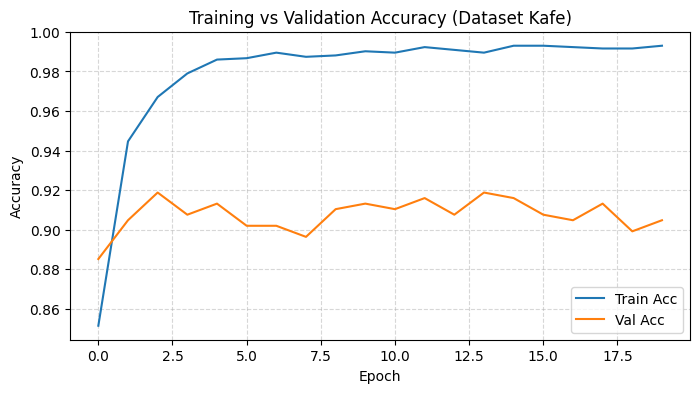

In [11]:
# Prediksi pada data testing
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print("Classification Report:\n", classification_report(y_test, y_pred, target_names=['Negatif (0)', 'Positif (1)']))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# Visualisasi kurva akurasi training vs validation
plt.figure(figsize=(8, 4))
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Training vs Validation Accuracy (Dataset Kafe)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [12]:
# 1. Simpan Model Keras (.h5)
model.save('cafe_sentiment_model.h5')
print("✅ Model berhasil disimpan sebagai: cafe_sentiment_model.h5")

# 2. Simpan Scaler (.pkl)
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("✅ Scaler berhasil disimpan sebagai: scaler.pkl")

# 3. Simpan TF-IDF Vectorizer (.pkl) untuk kebutuhan deployment
with open('tfidf.pkl', 'wb') as f:
    pickle.dump(tfidf, f)
print("✅ Vectorizer berhasil disimpan sebagai: tfidf.pkl")

✅ Model berhasil disimpan sebagai: cafe_sentiment_model.h5
✅ Scaler berhasil disimpan sebagai: scaler.pkl
✅ Vectorizer berhasil disimpan sebagai: tfidf.pkl
